You will build a model for the membrane potential ($V$)  based on the passive flow of potassium ($K^+$)
and sodium ($Na^+$) ions through leak channels. Modify the below template based on the ODEs.
The membrane potential dynamics are described by the equation:
$$C_m \frac{dV}{dt} = - I_{ion} = -(I_k + I_{Na}) $$
where $C_m$ is the membrane capacitance and the ionic currents are modeled as:
$$I_K = g_K(V − E_K)$$
$$I_{Na} = g_{Na}(V − E_{Na})$$
Here, $g_K$ and $g_{Na}$ are the constant conductances for the leak channels, and $E_K$ and $E_{Na}$ are the Nernst
potentials for each ion.
Use the following physiological parameters:
* $C_m = 1 (\mu F / cm^2)$
* $g_k = 0.3 (m S / cm^2)$
* $g_{Na} = 0.015 (mS/cm^2)$
* $E_k = -75 (mV)$
* $E_{Na} = 55 (mV)$

In [5]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [6]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Modelling_the_Cell_Membrane_Potential")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "Cm": 1,
    "gK": 0.3,
    "gNa" : 0.015,
    "EK" : -75,
    "ENa" : 55
}

# Define aux functions
fnspecs = {
    "IK": (['V'], "gK*(V - EK)"),
    "INa": (['V'], "gNa*(V - ENa)"),
}


# Define the ODEs.
varspecs = {
    "V": "1/Cm * -1*(IK(V) + INa(V))"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": 0,
}

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-70, 0],
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...


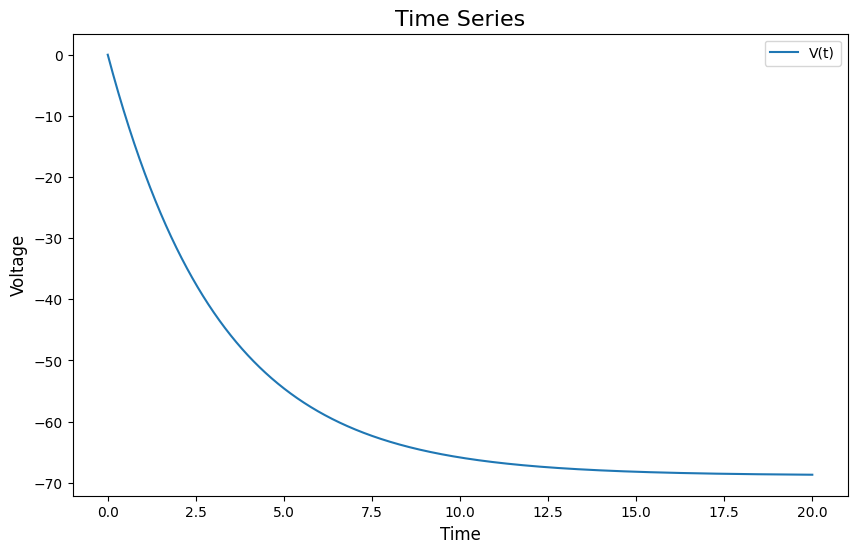

{'V': array([-68.80952381])}


In [7]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fig_1, ax_1 = plt.subplots(figsize=(10, 6))
ax_1.plot(points['t'], points['V'], label='V(t)')
ax_1.set_title('Time Series', fontsize=16)
ax_1.set_xlabel('Time', fontsize=12)
ax_1.set_ylabel('Voltage', fontsize=12)
plt.legend()
plt.show()

# Now find the steady state and compare it with the analyical solution
fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]
print(fp_coord)

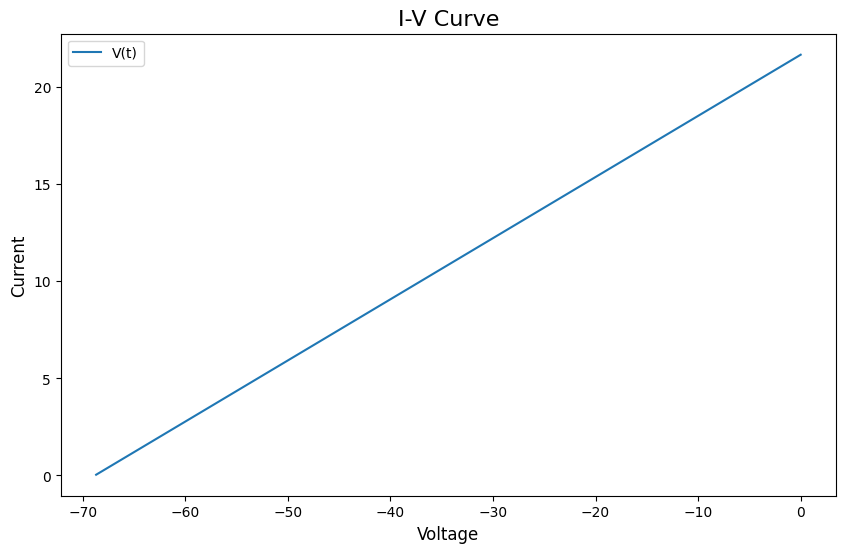

In [8]:
# Now plot the I-V curve. We have previously integrated the system so we have the potential values.
# We can define the curent by using lambda expressions. lambda variables : expression.
I_k = lambda V: pars["gK"] * (V - pars["EK"])
I_Na = lambda V: pars["gNa"] * (V - pars["ENa"])
I_ion = lambda V: I_k(V) + I_Na(V)

fig_2, ax_2 = plt.subplots(figsize=(10, 6))
ax_2.plot(points["V"], I_ion(points["V"]), label='V(t)')
ax_2.set_title('I-V Curve', fontsize=16)
ax_2.set_xlabel('Voltage', fontsize=12)
ax_2.set_ylabel('Current', fontsize=12)
plt.legend()
plt.show()

**Excercise:** Now, let’s make the model more realistic by including the $Na^+/K^+$ pump, which actively transports ions
to counteract the passive leaks and maintain concentration gradients. The pump contributes a constant
outward current, $I_p$.
The system equation becomes:
$$C_m \frac{dV}{dt} = -(I_k + I_{Na} + I_p) $$
Assume the pump current is $I_p = 0.5 (\mu A/cm^2)$
(Note: By convention, a positive sign indicates a net outward flow of positive charge).

In [9]:
# Define the new system 

Let’s analyse the behaviour of the excitable membrane model using two different tools: XPPAUT for
automated continuation and Python for direct visualisation.
The system equation is:
$$C_m \frac{dV}{dt} = -(g_k(V - E_k) + g_{Na}(V)(V-E_{Na})) + I_{app} $$
where the voltage-dependent sodium conductance is given by: 
$$g_{Na}(V) = \bar{g}_{Na}\left( 1 + \tanh{\left(\frac{V-V_{th}}{V_{slope}}\right)} \right) $$
For this task, use the following parameters: $\bar{g}_{Na} = 0.5, V_{th} = −20 mV, V_{slope} = 5 mV$, and a potassium
leak conductance of $g_K = 1.1 mS/cm^2$


In [10]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="threshold_behaviour")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "Cm": 1,
    "gK": 1.1,
    "g_Na" : 0.5, # g_Na denotes \bar{g}Na
    "EK" : -75,
    "ENa" : 55,
    "Vth" : -20,
    "Vs" : 5, # slope
    "Ip" : 0,
}

# Define aux functions
fnspecs = {
    "gNa": (['V'], "g_Na*(1+ tanh((V - Vth) / Vs))"),
}


# Define the ODEs.
varspecs = {
    "V": "1/Cm * -(gK * (V - EK) + gNa(V)*(V-ENa)) + Ip"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": 0,
}

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-70, 0],
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...


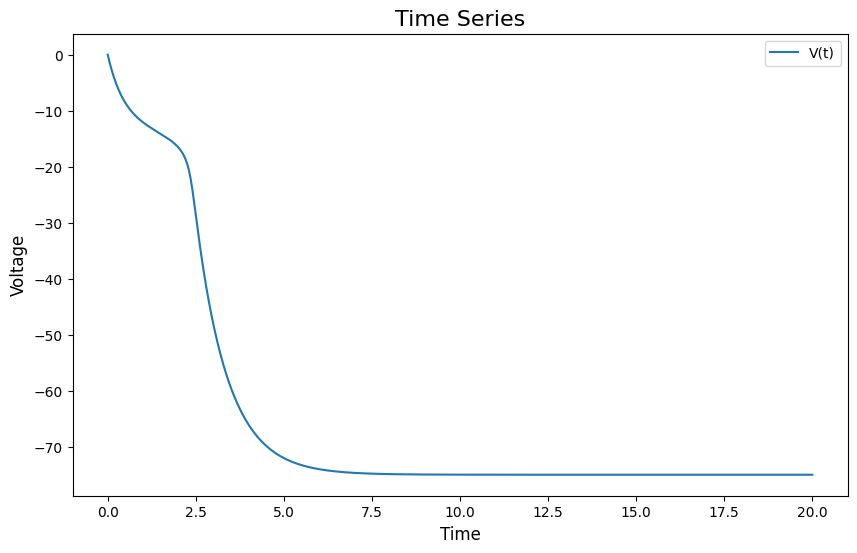

{'V': array([-74.99999997])}


In [11]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fig_1, ax_1 = plt.subplots(figsize=(10, 6))
ax_1.plot(points['t'], points['V'], label='V(t)')
ax_1.set_title('Time Series', fontsize=16)
ax_1.set_xlabel('Time', fontsize=12)
ax_1.set_ylabel('Voltage', fontsize=12)
plt.legend()
plt.show()

# Now find the steady state and compare it with the analyical solution
fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]
print(fp_coord)

In [12]:
# 3. Start Bifurcation Analysis
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

PyCont = dst.ContClass(ode_sys)
PCargs_EQ = dst.args(name='EQ1', type='EP-C')  # Equilibrium curve
PCargs_EQ.freepars = ['Ip'] # Parameter we want to bifurcate against
PCargs_EQ.MaxNumPoints = 200 # Maximum number of points, continuation will stop if exceeds this limit
PCargs_EQ.MaxStepSize = 1 # Defines the maximum step size at each step of continuation, this is an important parameter and it will depend on the system
PCargs_EQ.MinStepSize = 1e-3 # Defines the minimum step size at each step of continuation. Depends on the system
PCargs_EQ.LocBifPoints = 'LP' # Specifies the points to look for. LP denotes for limit point aka saddle point.
PCargs_EQ.SaveEigen = True
PCargs_EQ.SaveJacobian = True
PCargs_EQ.verbosity = 2
PCargs_EQ.initpoint = fp_coord
PyCont.newCurve(PCargs_EQ)

# Forward continuation
PyCont['EQ1'].forward()


Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
V  =  -28.26721363260002
Ip  =  48.4637570899848

Eigenvalues = 

     (-0.000000,0.000000)


a = 0.19738511950843454


Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
V  =  -13.882980727433987
Ip  =  3.833806589885981

Eigenvalues = 

     (0.000000,0.000000)


a = 0.3690097297355995



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (Ip, V) space')

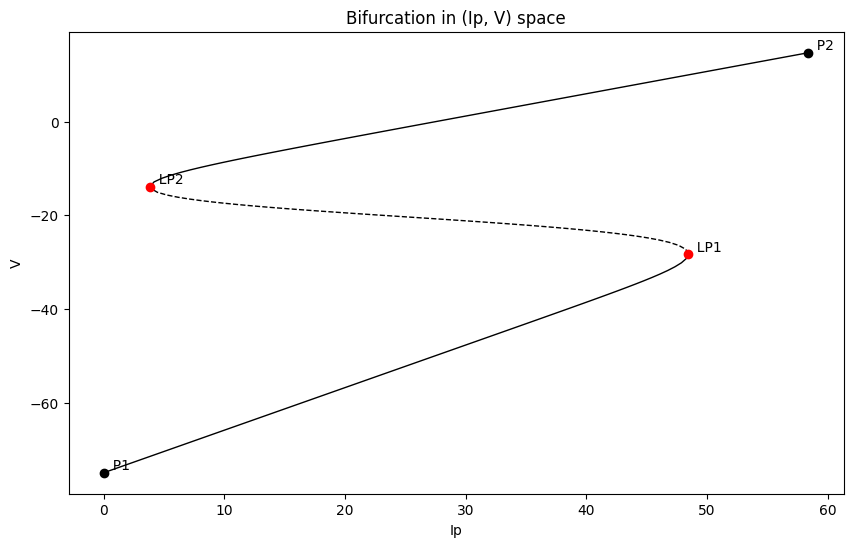

In [45]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
PyCont.display(('Ip', 'V'), stability=True)
plt.title("Bifurcation in (Ip, V) space")